# NN_L12_next_token

**Top next-token probabilities of Qwen2.5-1.5B-Instruct after the start of a sentence from the latest ECB speech, at temperatures 0.5, 1 and 2, with the entropy of each distribution.**

Neural Networks and Deep Learning (NN), Lecture 12 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L12/NN_L12_next_token/NN_L12_next_token.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

entropy at T=0.5 (nats) = 1.74   [next.entropy.t05]
entropy at T=1.0 (nats) = 6.2   [next.entropy.t10]
entropy at T=2.0 (nats) = 10.29   [next.entropy.t20]
probability of the top token at T=1 (%) = 10.1   [next.top1_p]


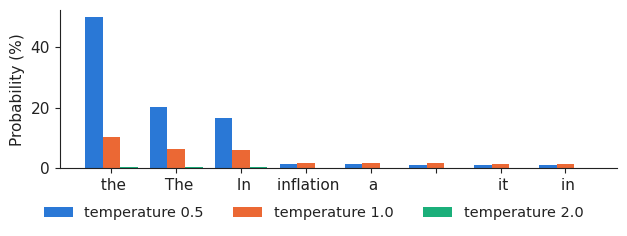

In [3]:
RES = REPO + 'lectures/L12/results/'
import json, urllib.request
def load_json(name):
    p = RES + name
    return json.load(open(p)) if os.path.exists(p) else json.load(urllib.request.urlopen(p))
NT = load_json('lm_outputs.json')['next_token']
for T in ('0.5', '1.0', '2.0'):
    show('next.entropy.t' + T.replace('.', ''), f'entropy at T={T} (nats)', round(NT[T]['entropy'], 2))
show('next.top1_p', 'probability of the top token at T=1 (%)', round(100 * NT['1.0']['p'][0], 1))
toks = NT['1.0']['tok']
fig, ax = plt.subplots(figsize=(6.4, 2.4))
for j, (T, c) in enumerate([('0.5', PAL['data']), ('1.0', PAL['model']), ('2.0', PAL['benchmark'])]):
    d = dict(zip(NT[T]['tok'], NT[T]['p']))
    ax.bar(np.arange(len(toks)) + (j - 1) * 0.27, [100 * d.get(t, np.nan) for t in toks], 0.27, color=c, label=f'temperature {T}')
ax.set_xticks(range(len(toks)))
ax.set_xticklabels([repr(t)[1:-1] for t in toks])
ax.set_ylabel('Probability (%)')
legend_bottom(fig, ncol=3)
fig.tight_layout(rect=(0, 0.1, 1, 1))
fig.savefig('next_token.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()